## Image Restoration

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
imgpath = '/content'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

print(os.path.exists(imgpath + '/dentalXray-pepper-noise.tif'))

True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
f = plt.imread(imgpath+'/test-pattern.tif')
f.shape

(604, 604)

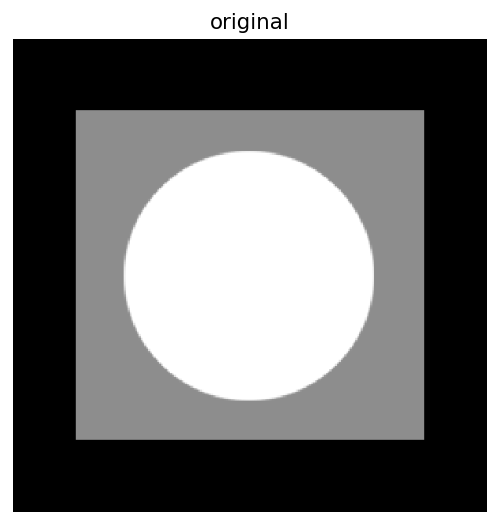

In [ ]:
plt.figure(dpi=128)
plt.imshow(f, cmap='gray', aspect = 'equal')
plt.axis('off')
plt.title('original')
plt.show()

### Gaussian Noise

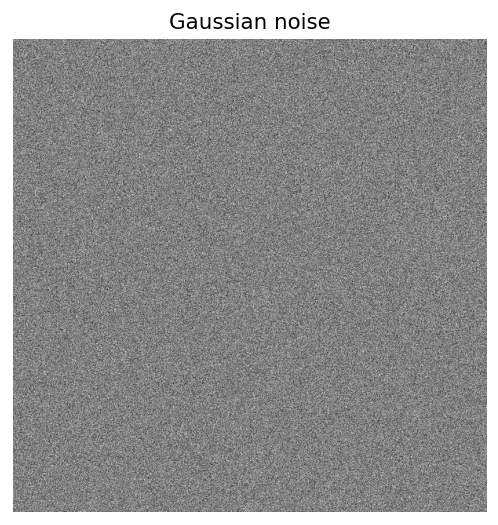

In [ ]:
n_gauss = np.random.normal(0,32,f.shape)
plt.figure(dpi=128)
plt.imshow(n_gauss, cmap='gray', aspect = 'equal')
plt.axis('off')
plt.title('Gaussian noise')
plt.show()

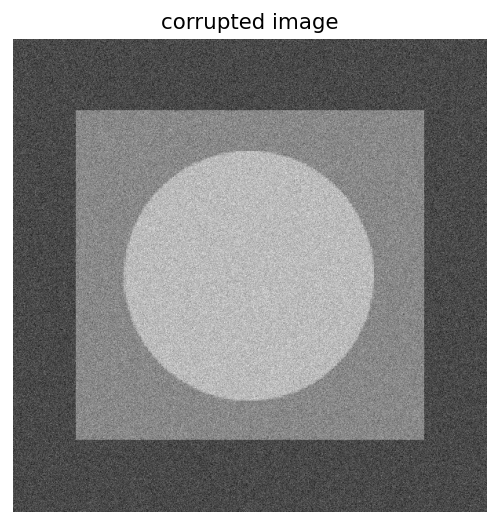

In [ ]:
f_n = f + n_gauss
plt.figure(dpi=128)
plt.imshow(f_n,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('corrupted image')
plt.show()

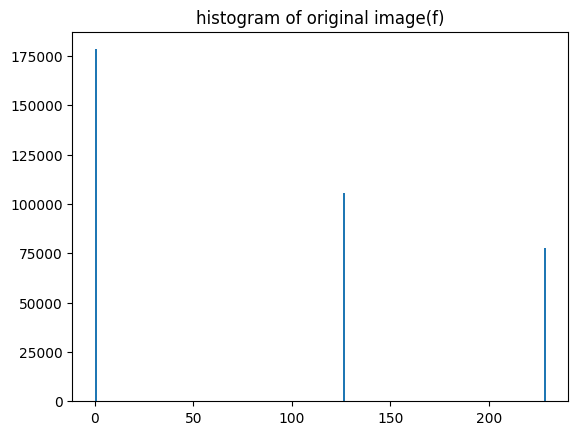

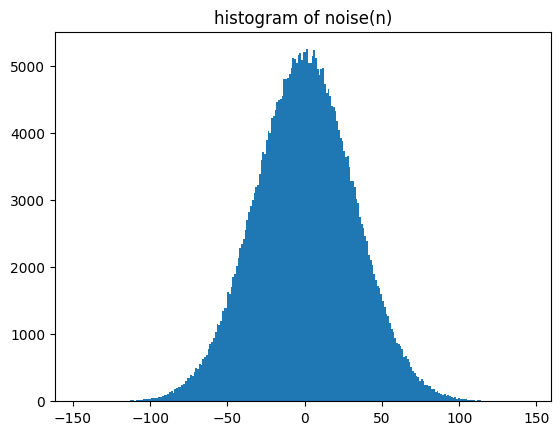

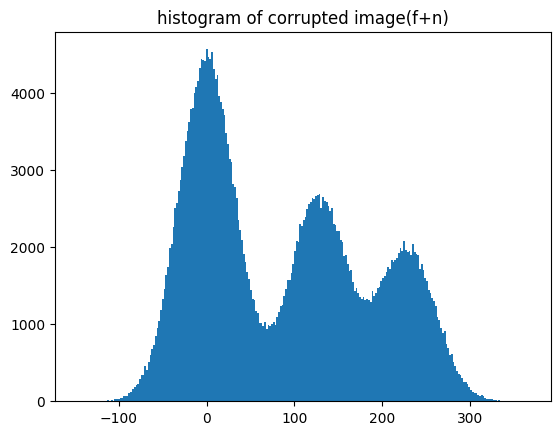

In [ ]:
plt.hist(f.ravel(),256)
plt.title('histogram of original image(f)')
plt.show()
plt.hist(n_gauss.ravel(),256)
plt.title('histogram of noise(n)')
plt.show()
plt.hist(f_n.ravel(),256)
plt.title('histogram of corrupted image(f+n)')
plt.show()

### Salt and Pepper Noise

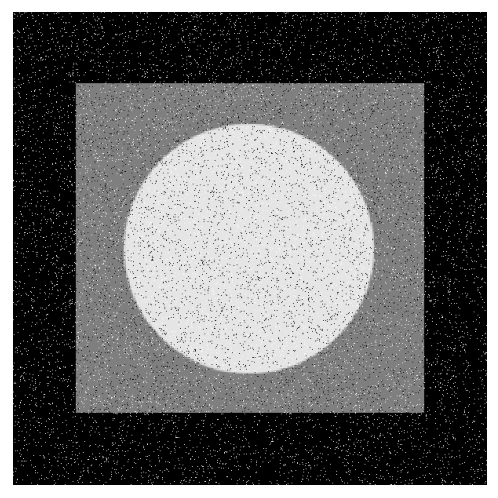

In [ ]:
sp = np.random.randint(0,100,np.shape(f))
f_sp = f.copy()
f_sp[sp<3] = 0
f_sp[sp>96] = 255

plt.figure(dpi=128)
plt.imshow(f_sp,cmap='gray',aspect='equal')
plt.axis('off')
plt.show()

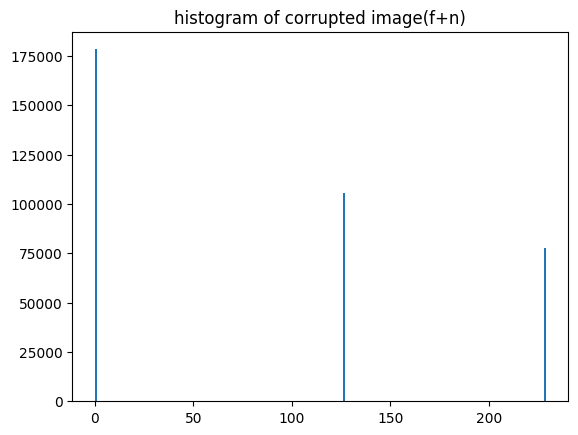

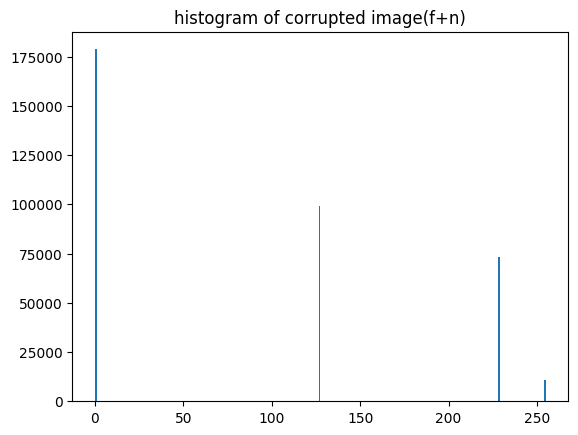

In [ ]:
plt.hist(f.ravel(),256)
plt.title('histogram of corrupted image(f+n)')
plt.show()

plt.hist(f_sp.ravel(),256)
plt.title('histogram of corrupted image(f+n)')
plt.show()

### Mean vs Median Filtering

In [ ]:
SS = 7 # kernel size (square kernel)
ss = int((SS-1)/2)
r_median = np.zeros(np.shape(f_sp))
r_mean = np.zeros(np.shape(f_sp))

In [ ]:
for x in range(ss,np.size(f_sp,0)-ss):
  for y in range(ss,np.size(f_sp,1)-ss):
    Sxy = f_sp[x-ss:x-ss+SS,y-ss:y-ss+SS]
    r_mean[x,y] = np.mean(Sxy)
    r_median[x,y] = np.median(Sxy)

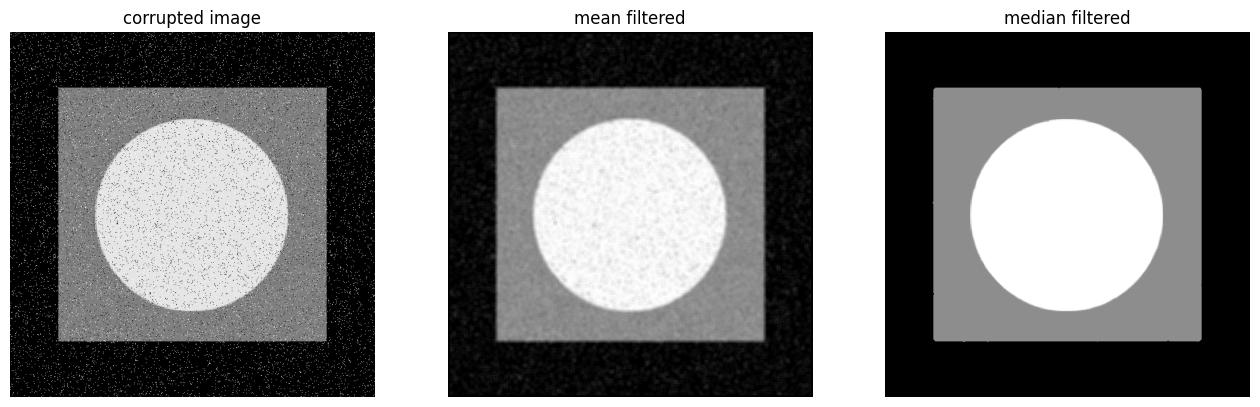

In [ ]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f_sp,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('corrupted image')
plt.subplot(132)
plt.imshow(r_mean,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('mean filtered')
plt.subplot(133)
plt.imshow(r_median,cmap='gray',aspect='equal')
plt.axis('off')
plt.title('median filtered')
plt.show()

## Adaptive Local Noise Reduction

In [ ]:
# Adaptive local noise reduction
f = f_n

std_eta = 16
SS = 5

ss = int((SS-1)/2)
r_amean = np.zeros(np.shape(f))
for x in range(ss,np.size(f,0)-ss):
  for y in range(ss,np.size(f,1)-ss):
    Sxy = f[x-ss:x-ss+SS,y-ss:y-ss+SS]
    r_mean[x,y] = np.mean(Sxy)
    std_Sxy = np.std(Sxy)
    r_amean[x,y]=f[x,y]-((std_eta*std_eta)/(std_Sxy*std_Sxy))*(f[x,y]-np.mean(Sxy))

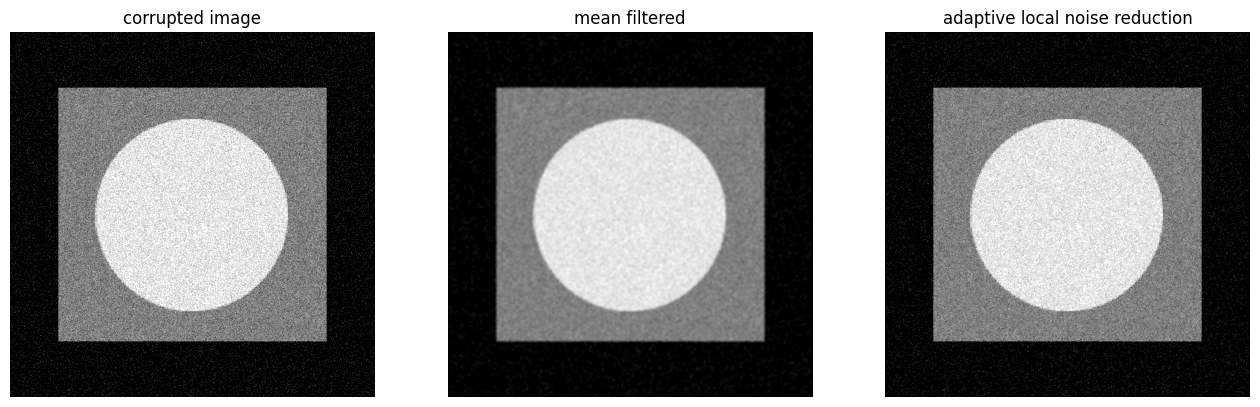

In [ ]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f_n,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('corrupted image')
plt.subplot(132)
plt.imshow(r_mean,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('mean filtered')
plt.subplot(133)
plt.imshow(r_amean,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('adaptive local noise reduction')
plt.show()

## Adaptive Median Filtering

In [ ]:
# Adaptive Median Filtering
#f = f_sp
f = plt.imread(imgpath+'/circuitboard-saltandpep.tif')
SS_vals = np.array([3, 5, 7])
r_amedian = np.zeros(np.shape(f))
r_median = np.zeros(np.shape(f))
r_case = np.zeros(np.shape(f))

ss_max = int((np.max(SS_vals)-1)/2)
for x in range(ss_max,np.size(f,0)-ss_max):
  for y in range(ss_max,np.size(f,1)-ss_max):
    flag_go = 1
    cnt = 0
    z_xy = f[x,y]
    for SS in SS_vals:
      ss = int((SS-1)/2)
      Sxy = f[x-ss:x-ss+SS,y-ss:y-ss+SS]
      z_med = np.median(Sxy)
      z_min = np.min(Sxy)
      z_max = np.max(Sxy)

      if cnt==0:
        r_median[x,y] = z_med

      if z_min<z_med and z_med<z_max:
        if z_min<z_xy and z_xy<z_max:
          r_amedian[x,y] = z_xy
          flag_go = 0
        else:
          r_amedian[x,y] = z_med
          flag_go = 0
      else:
        if SS == np.max(SS_vals):
          r_amedian[x,y] = z_med
          flag_go = 0

      if flag_go==0:
        r_case[x,y] = cnt
        break
      cnt = cnt+1

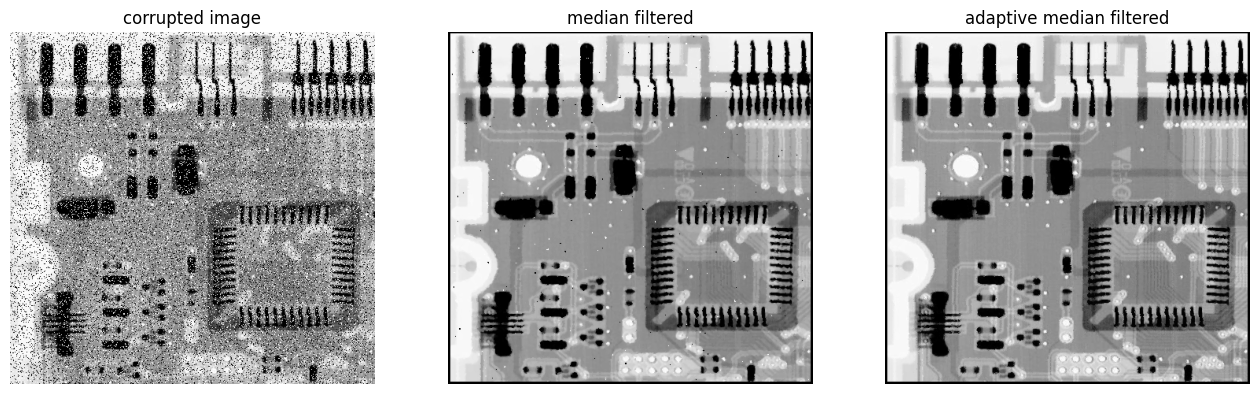

In [ ]:
plt.figure(figsize=(16,9))
plt.subplot(131)
plt.imshow(f,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('corrupted image')
plt.subplot(132)
plt.imshow(r_median,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('median filtered')
plt.subplot(133)
plt.imshow(r_amedian,cmap='gray',aspect='equal',vmin=0,vmax=255)
plt.axis('off')
plt.title('adaptive median filtered')
plt.show()

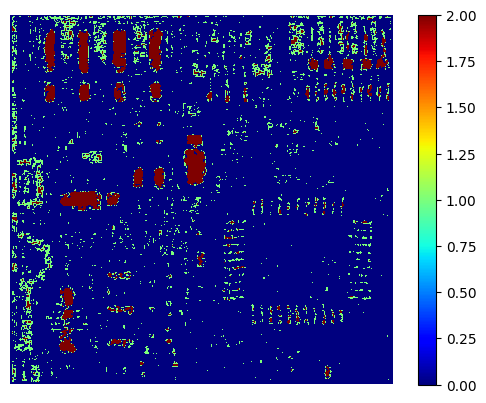

In [ ]:
plt.imshow(r_case,cmap='jet',interpolation='nearest')
plt.axis('off')
plt.colorbar()
plt.show()

## Exercise
- 두 개의 noisy image를 각각 f1, f2로 불러오고 적절한 restoration(denoising)을 수행해보자.

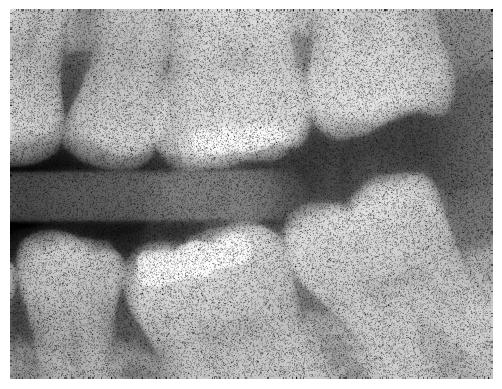

In [ ]:
#f1 = plt.imread(imgpath+'/galaxy-pair-noisy.tif')
f2 = plt.imread(imgpath+'/dentalXray-pepper-noise.tif')

plt.imshow(f2, cmap='gray')
plt.axis('off')
plt.show()

- 복원코드를 직접 작성해보기.

In [ ]:
# Arithmetic Mean Filter

SS = 3
ss = int((SS-1)/2)

r_mean = f2.astype(float).copy()

for x in range(ss, f2.shape[0]-ss):
    for y in range(ss, f2.shape[1]-ss):
        Sxy = f2[x-ss:x+ss+1, y-ss:y+ss+1]
        r_mean[x,y] = np.mean(Sxy)


- 복원된 f1, f2를 시각화하기

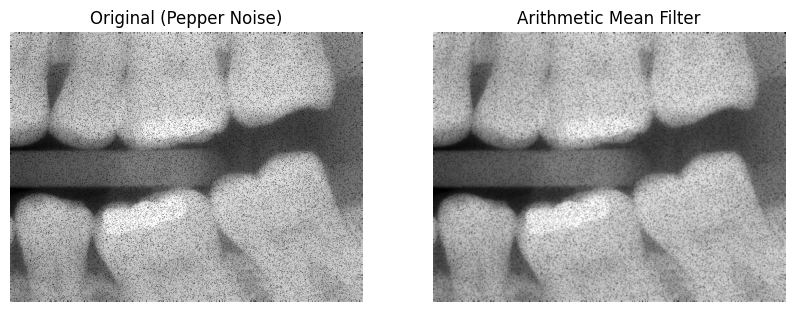

In [ ]:
# Arithmetic Mean 필터 결과 비교

plt.figure(figsize=(10, 4))

# 원본 영상
plt.subplot(1, 2, 1)
plt.imshow(f2, cmap='gray')
plt.title('Original (Pepper Noise)')
plt.axis('off')

# Arithmetic Mean 필터 적용 영상
plt.subplot(1, 2, 2)
plt.imshow(r_mean, cmap='gray')
plt.title('Arithmetic Mean Filter')
plt.axis('off')

plt.show()


In [ ]:
# Median Filter

SS = 3
ss = int((SS-1)/2)

r_median = f2.astype(float).copy()

for x in range(ss, f2.shape[0]-ss):
    for y in range(ss, f2.shape[1]-ss):
        Sxy = f2[x-ss:x+ss+1, y-ss:y+ss+1]
        r_median[x,y] = np.median(Sxy)


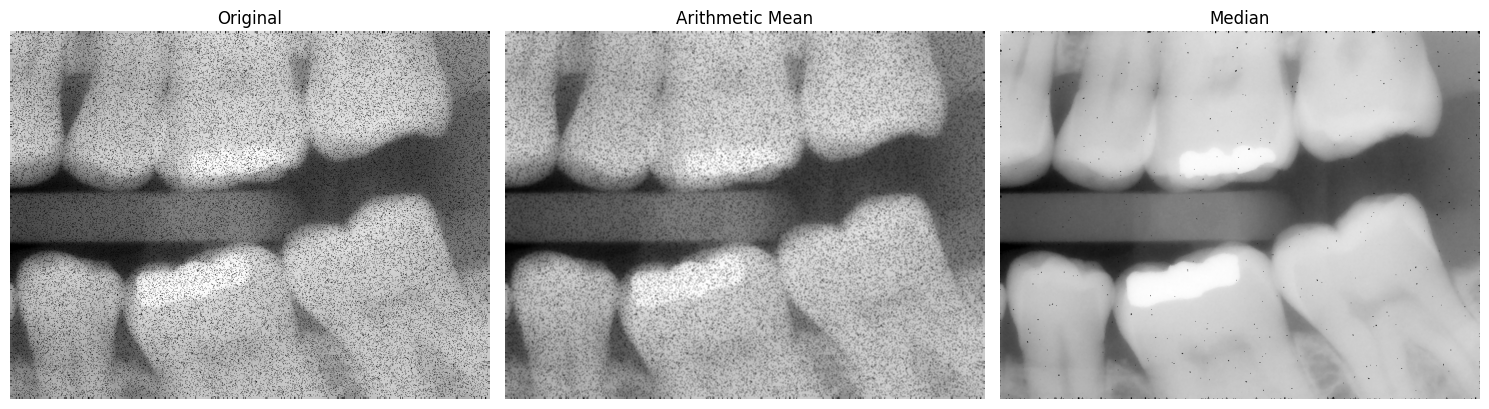

In [ ]:
# Original vs Arithmetic Mean vs Median

plt.figure(figsize=(15, 5))

# 1. 원본 영상
plt.subplot(1, 3, 1)
plt.imshow(f2, cmap='gray')
plt.title('Original')
plt.axis('off')

# 2. Arithmetic Mean
plt.subplot(1, 3, 2)
plt.imshow(r_mean, cmap='gray')
plt.title('Arithmetic Mean')
plt.axis('off')

# 3. Median
plt.subplot(1, 3, 3)
plt.imshow(r_median, cmap='gray')
plt.title('Median')
plt.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
# Adaptive Local Noise Reduction

SS = 5
ss = int((SS-1)/2)

# 입력 영상의 intensity 범위 확인
print(f2.dtype, np.min(f2), np.max(f2))

# 잡음 표준편차 (실습용 초기 설정)
std_eta = 16.0 if np.max(f2) > 1 else 16.0 / 255.0

r_adaptive = f2.astype(float).copy()

for x in range(ss, f2.shape[0]-ss):
    for y in range(ss, f2.shape[1]-ss):
        Sxy = f2[x-ss:x+ss+1, y-ss:y+ss+1]

        local_mean = np.mean(Sxy)
        local_var = np.var(Sxy)

        noise_var = std_eta ** 2
        weight = min(1.0, noise_var / max(local_var, 1e-10))

        r_adaptive[x,y] = f2[x,y] - weight * (f2[x,y] - local_mean)


uint8 0 255


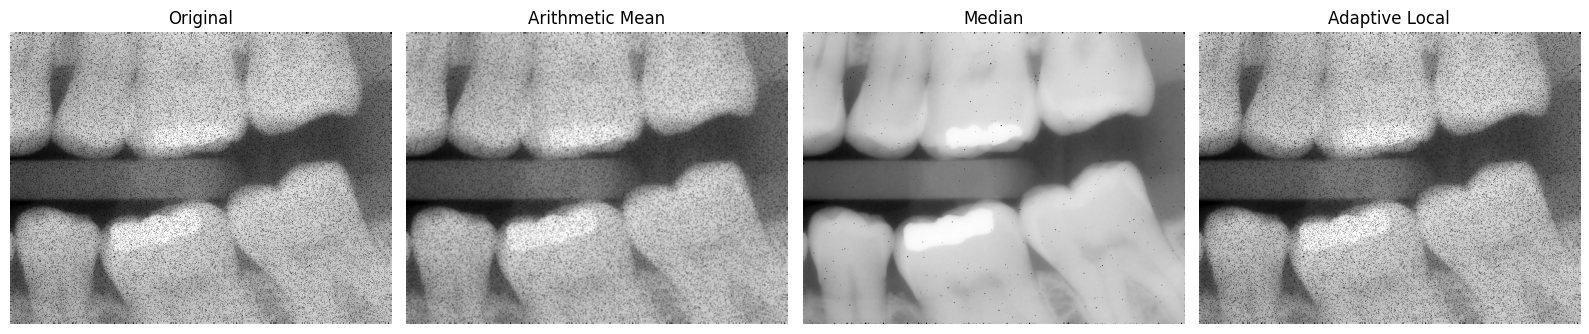

In [ ]:
# Comparison of Three Denoising Filters

plt.figure(figsize=(16, 5))

# 1. Original
plt.subplot(1, 4, 1)
plt.imshow(f2, cmap='gray', vmin=0, vmax=255)
plt.title('Original')
plt.axis('off')

# 2. Arithmetic Mean
plt.subplot(1, 4, 2)
plt.imshow(r_mean, cmap='gray', vmin=0, vmax=255)
plt.title('Arithmetic Mean')
plt.axis('off')

# 3. Median
plt.subplot(1, 4, 3)
plt.imshow(r_median, cmap='gray', vmin=0, vmax=255)
plt.title('Median')
plt.axis('off')

# 4. Adaptive Local Noise Reduction
plt.subplot(1, 4, 4)
plt.imshow(r_adaptive, cmap='gray', vmin=0, vmax=255)
plt.title('Adaptive Local')
plt.axis('off')

plt.tight_layout()
plt.show()


- 복원된 f1, f2를 그림파일로 저장하기

In [ ]:
# Save denoised Dental X-ray images

plt.imsave('HW02_mean.png', r_mean, cmap='gray', vmin=0, vmax=255)

plt.imsave('HW02_median.png', r_median, cmap='gray', vmin=0, vmax=255)

plt.imsave('HW02_adaptive.png', r_adaptive, cmap='gray', vmin=0, vmax=255)

print('All denoised images saved successfully!')


All denoised images saved successfully!


HW02 - Image Restoration 결과 분석

1. Arithmetic Mean Filter

주변 픽셀의 평균을 이용해 잡음을 완화했지만, 검은 점들이 상당 부분 남아 있었다. 영상이 약간 부드러워지는 효과가 나타났다.

2. Median Filter

세 필터 중 Pepper noise가 가장 뚜렷하게 감소했다. 치아의 전체적인 윤곽도 비교적 잘 유지되었다.

3. Adaptive Local Noise Reduction

국소 평균과 분산을 이용해 잡음을 감소시켰지만, 이번 영상에서는 Median보다 잡음이 많이 남았다. 잡음 표준편차는 16으로 가정했다.

Conclusion

이번 실험의 시각적 비교에서는 Median Filter가 가장 효과적이었다.